In [1]:

!pip install kagglehub

import kagglehub

path = kagglehub.dataset_download(
    "austinreese/craigslist-carstrucks-data"
)

print("Dataset downloaded successfully!")


Using Colab cache for faster access to the 'craigslist-carstrucks-data' dataset.
Dataset downloaded successfully!


In [2]:

import pandas as pd
import os

# Load the dataset
df = pd.read_csv(os.path.join(path, "vehicles.csv"))

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


/tmp/ipykernel_1877/996330399.py:5: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(path, "vehicles.csv"))


Dataset Shape: (295451, 41)

Column Names:
['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county', 'state', 'lat', 'long', 'posting_date', 'seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_count', 'image_urls', 'delivery_available', 'odometer_broken', 'odometer_rolled_over', 'monthly_payment', 'other_attributes']

First 5 Rows:


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN


In [4]:

# Convert price from text to numeric

df["price"] = pd.to_numeric(
    df["price"].astype(str).str.replace(
        r"[$,]", "", regex=True
    ).str.strip(),
    errors="coerce"
)

print("Price Data Type:", df["price"].dtype)

print("\nPrice Statistics:")
print(df["price"].describe())

print("\nInvalid Prices:", (df["price"] <= 0).sum())

print("\nMissing Prices:", df["price"].isnull().sum())

print("\nInvalid Years:")
print(((df["year"] < 1900) | (df["year"] > 2026)).sum())

print("\nInvalid Odometer Values:")
print((df["odometer"] < 0).sum())


Price Data Type: float64

Price Statistics:
count    2.954510e+05
mean     3.384656e+18
std      1.839743e+21
min      0.000000e+00
25%      6.200000e+03
50%      1.250000e+04
75%      2.250000e+04
max      1.000000e+24
Name: price, dtype: float64

Invalid Prices: 10288

Missing Prices: 0

Invalid Years:
535

Invalid Odometer Values:
0


In [34]:

# Step 4: Data Quality Assessment

# Convert price column to numeric, forcing errors (non-numeric strings) to NaN
df["price"] = pd.to_numeric(df["price"], errors="coerce")

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate IDs:", df["id"].duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nPrice Statistics:")
print(df["price"].describe())

print("\nInvalid Prices:", (df["price"] <= 0).sum())

print("\nInvalid Years:")
print(((df["year"] < 1900) | (df["year"] > 2026)).sum())

print("\nInvalid Odometer Values:")
print((df["odometer"] < 0).sum())


Dataset Shape: (295451, 41)

Missing Values:
size                   295451
county                 295451
other_attributes       291688
monthly_payment        289398
updated_date           179711
address_street         138758
condition              135490
VIN                    121119
cylinders               80167
paint_color             74718
drive                   70375
type                    15809
address_city            14471
address_country         14471
address_state           14471
address_postal_code     14471
manufacturer            10792
title_status             6816
odometer                 4036
image_url                3538
image_urls               3538
model                    3359
transmission             1556
fuel                     1131
lat                       149
long                      149
year                       26
description                 6
title                       5
dtype: int64

Duplicate Rows: 0

Duplicate IDs: 0

Data Types:
id                    

In [35]:

# Step 5: Investigate Invalid Prices

print("Cars with price = 0:")
print((df["price"] == 0).sum())

print("\nCars with negative prices:")
print((df["price"] < 0).sum())

print("\nCars with price above $200,000:")
print((df["price"] > 200000).sum())

print("\nPrice Percentiles:")
print(df["price"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

print("\nTop 10 Highest Prices:")
display(
    df.nlargest(10, "price")[
        ["price", "year", "manufacturer", "model"]
    ]
)


Cars with price = 0:
10288

Cars with negative prices:
0

Cars with price above $200,000:
424

Price Percentiles:
0.01        0.0
0.05      995.0
0.25     6200.0
0.50    12500.0
0.75    22500.0
0.95    49993.0
0.99    89900.0
Name: price, dtype: float64

Top 10 Highest Prices:


,price,year,manufacturer,model
120108,1.000000e+24,2001.0,mazda,protege
50847,1.111111e+16,1991.0,ford,f-150
101596,1.000000e+12,1950.0,gmc,NaN
168494,1.111111e+11,2017.0,chevrolet,NaN
120040,1.111111e+10,2017.0,NaN,any
35260,1.111111e+09,1967.0,chevrolet,NaN
34758,1.000000e+09,2007.0,ram,2500hd
55472,9.876543e+08,2012.0,chevrolet,silverado
55474,9.876543e+08,2016.0,chevrolet,silverado 2500
291379,9.876543e+08,2002.0,ram,3500


In [36]:

# Step 6: Clean Invalid Prices

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove zero and negative prices
df_clean = df_clean[
    df_clean["price"] > 0
].copy()

# Remove clearly unrealistic prices
# $1,000,000 is a preliminary upper limit
df_clean = df_clean[
    df_clean["price"] <= 1000000
].copy()

# Compare before and after
print("Original Rows:", len(df))
print("Rows After Price Cleaning:", len(df_clean))
print("Rows Removed:", len(df) - len(df_clean))

print("\nCleaned Price Statistics:")
print(df_clean["price"].describe())


Original Rows: 295451
Rows After Price Cleaning: 285092
Rows Removed: 10359

Cleaned Price Statistics:
count     285092.000000
mean       18313.384813
std        20541.063017
min            1.000000
25%         6950.000000
50%        12995.000000
75%        22995.000000
max      1000000.000000
Name: price, dtype: float64


In [8]:

# Check remaining high-price vehicles

print("Prices above $200,000:")
print((df_clean["price"] > 200000).sum())

print("\nTop 10 Remaining Prices:")
display(
    df_clean.nlargest(10, "price")[
        ["price", "year", "manufacturer", "model"]
    ]
)


Prices above $200,000:
353

Top 10 Remaining Prices:


,price,year,manufacturer,model
208998,1000000.0,1981.0,NaN,El Camino
281962,1000000.0,2014.0,dodge,tradesman
230539,999999.0,2022.0,toyota,camry
85167,799000.0,2024.0,mercedes-benz,amg g 63
117533,700000.0,2006.0,ford,gt
227863,700000.0,2006.0,ford,gt
214440,654321.0,1949.0,mercury,NaN
59153,589980.0,2022.0,ferrari,f8 spider
262388,589980.0,2022.0,ferrari,f8 spider
261480,560900.0,2026.0,NaN,rolls-royce cullinan


In [37]:

# Step 8: Inspect Year and Odometer

print("Missing Years:")
print(df_clean["year"].isnull().sum())

print("\nYear Statistics:")
print(df_clean["year"].describe())

print("\nCars Before 1900:")
print((df_clean["year"] < 1900).sum())

print("\nCars After 2026:")
print((df_clean["year"] > 2026).sum())

print("\nMissing Odometer:")
print(df_clean["odometer"].isnull().sum())

print("\nOdometer Statistics:")
print(df_clean["odometer"].describe())

print("\nCars Above 500,000 Miles:")
print((df_clean["odometer"] > 500000).sum())


Missing Years:
15

Year Statistics:
count    285077.000000
mean       2012.591005
std          11.655295
min        1900.000000
25%        2010.000000
50%        2015.000000
75%        2019.000000
max        2027.000000
Name: year, dtype: float64

Cars Before 1900:
0

Cars After 2026:
444

Missing Odometer:
3668

Odometer Statistics:
count    2.814240e+05
mean     1.151950e+05
std      1.613347e+05
min      1.000000e+00
25%      6.895100e+04
50%      1.085960e+05
75%      1.482860e+05
max      1.000000e+07
Name: odometer, dtype: float64

Cars Above 500,000 Miles:
730


In [38]:

# Step 9: Clean Year and Odometer

# Remove missing and invalid years
df_clean = df_clean.dropna(subset=["year"]).copy()

df_clean = df_clean[
    df_clean["year"].between(1900, 2027)
].copy()

# Flag suspicious odometer values
df_clean["odometer_outlier"] = (
    df_clean["odometer"] > 500000
).astype(int)

# Replace suspicious values with missing
df_clean.loc[
    df_clean["odometer"] > 500000, "odometer"
] = float("nan")

# Keep missing odometer values for later imputation
print("Rows After Cleaning:", len(df_clean))

print("\nMissing Odometer:")
print(df_clean["odometer"].isnull().sum())

print("\nYear Range:")
print(df_clean["year"].min(), "-", df_clean["year"].max())

print("\nOdometer Statistics:")
print(df_clean["odometer"].describe())


Rows After Cleaning: 285077

Missing Odometer:
4396

Year Range:
1900.0 - 2027.0

Odometer Statistics:
count    280681.000000
mean     110965.731485
std       61838.302191
min           1.000000
25%       68774.000000
50%      108308.000000
75%      148000.000000
max      500000.000000
Name: odometer, dtype: float64


In [39]:

# Step 10: Check Categorical Columns

categorical_columns = [
    "manufacturer",
    "model",
    "condition",
    "cylinders",
    "fuel",
    "title_status",
    "transmission",
    "drive",
    "type",
    "paint_color"
]

for col in categorical_columns:
    print("\n" + "=" * 40)
    print("Column:", col)
    print("Missing Values:", df_clean[col].isnull().sum())
    print("Unique Values:", df_clean[col].nunique())
    print("\nTop 10 Values:")
    print(df_clean[col].value_counts().head(10))



Column: manufacturer
Missing Values: 10448
Unique Values: 42

Top 10 Values:
manufacturer
ford         49330
chevrolet    32740
toyota       26137
honda        16760
nissan       13910
ram          13848
jeep         13039
subaru       10554
gmc          10272
bmw           9295
Name: count, dtype: int64

Column: model
Missing Values: 3280
Unique Values: 27321

Top 10 Values:
model
f-150             4150
1500              2686
silverado 1500    2353
civic             2039
camry             2030
outback           2018
accord            2015
forester          1975
2500              1831
wrangler          1747
Name: count, dtype: int64

Column: condition
Missing Values: 128651
Unique Values: 6

Top 10 Values:
condition
excellent    75955
good         50547
like new     19223
fair          6424
new           2292
salvage       1985
Name: count, dtype: int64

Column: cylinders
Missing Values: 76664
Unique Values: 8

Top 10 Values:
cylinders
4 cylinders     75034
6 cylinders     70692
8 cyl

In [40]:

# Step 11: Missing Values Summary

missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing %": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values(
        "Missing %", ascending=False
    )
)


,Missing Count,Missing %
size,285077,100.00
county,285077,100.00
other_attributes,281320,98.68
monthly_payment,279149,97.92
updated_date,173036,60.70
condition,128651,45.13
address_street,128544,45.09
VIN,117481,41.21
cylinders,76664,26.89
paint_color,71741,25.17


In [41]:

# Step 12: Select Relevant Features

selected_columns = [
    "price",
    "year",
    "manufacturer",
    "model",
    "condition",
    "cylinders",
    "fuel",
    "odometer",
    "title_status",
    "transmission",
    "drive",
    "type",
    "paint_color",
    "state",
    "seller_type"
]

df_prepared = df_clean[selected_columns].copy()

print("Dataset Shape:", df_prepared.shape)

print("\nMissing Values:")
display(df_prepared.isnull().sum().to_frame("Missing Count"))

print("\nFirst 5 Rows:")
display(df_prepared.head())


Dataset Shape: (285077, 15)

Missing Values:


,Missing Count
price,0
year,0
manufacturer,10448
model,3280
condition,128651
cylinders,76664
fuel,1020
odometer,4396
title_status,6631
transmission,1467



First 5 Rows:


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,seller_type
0,27999.0,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,4wd,SUV,grey,ca,dealer
1,2200.0,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,rwd,other,green,ca,owner
2,15999.0,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,4wd,SUV,white,ca,dealer
3,12000.0,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,fwd,convertible,blue,ca,owner
4,18999.0,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,rwd,coupe,orange,ca,dealer


In [42]:

# Step 13: Feature Engineering

# 1. Calculate car age
df_prepared["car_age"] = (
    2026 - df_prepared["year"]
).clip(lower=0)

# 2. Calculate average mileage per year
df_prepared["mileage_per_year"] = (
    df_prepared["odometer"] /
    (df_prepared["car_age"] + 1)
)

# 3. Identify selected luxury brands
luxury_brands = [
    "bmw", "mercedes-benz", "audi",
    "lexus", "porsche", "jaguar",
    "land rover", "bentley",
    "rolls-royce", "ferrari"
]

df_prepared["is_luxury"] = (
    df_prepared["manufacturer"]
    .astype("string")
    .str.lower()
    .isin(luxury_brands)
    .astype(int)
)

print("Dataset Shape:", df_prepared.shape)

print("\nNew Features:")
display(
    df_prepared[
        ["year", "car_age", "odometer",
         "mileage_per_year", "is_luxury"]
    ].head(10)
)

print("\nMissing Values in New Features:")
print(
    df_prepared[
        ["car_age", "mileage_per_year", "is_luxury"]
    ].isnull().sum()
)


Dataset Shape: (285077, 18)

New Features:


,year,car_age,odometer,mileage_per_year,is_luxury
0,2022.0,4.0,99179.0,19835.800000,0
1,1969.0,57.0,90000.0,1551.724138,0
2,2016.0,10.0,82896.0,7536.000000,0
3,1974.0,52.0,89687.0,1692.207547,0
4,2009.0,17.0,81724.0,4540.222222,0
5,2020.0,6.0,96104.0,13729.142857,0
6,2023.0,3.0,54131.0,13532.750000,0
7,2015.0,11.0,151055.0,12587.916667,0
8,2023.0,3.0,62969.0,15742.250000,0
9,2017.0,9.0,72493.0,7249.300000,0



Missing Values in New Features:
car_age                0
mileage_per_year    4396
is_luxury              0
dtype: int64


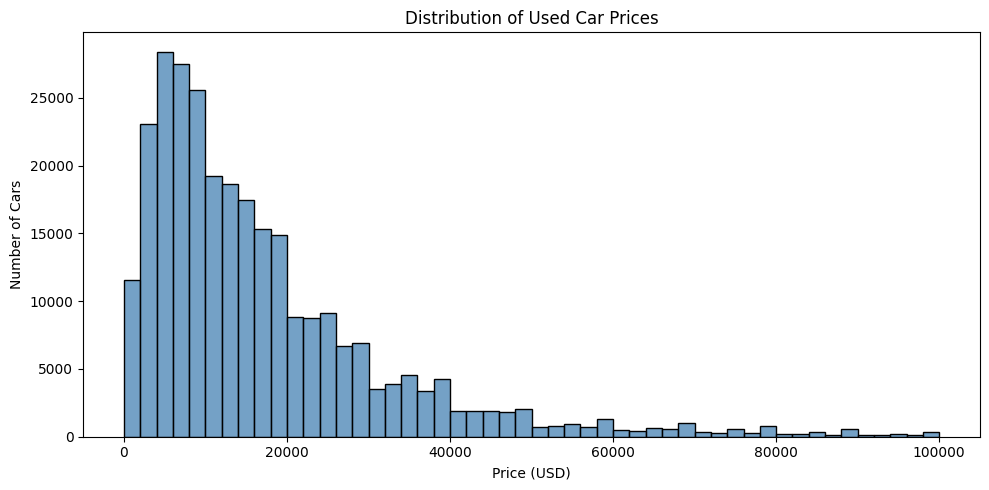

In [43]:

# Step 14: EDA - Price Distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_prepared[df_prepared["price"] <= 100000],
    x="price",
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


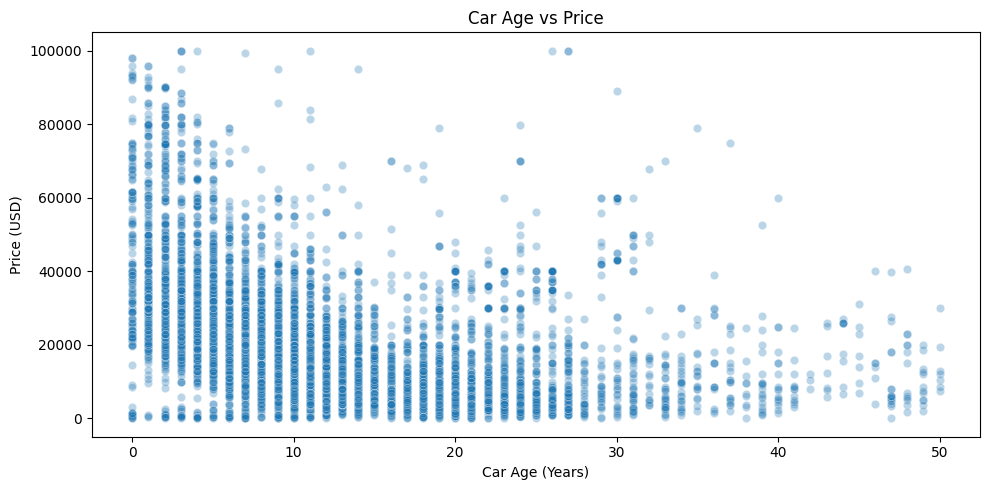

In [18]:

# Step 15: EDA - Car Age vs Price

import matplotlib.pyplot as plt
import seaborn as sns

# Use a sample for faster visualization
plot_data = df_prepared[
    (df_prepared["price"] <= 100000) &
    (df_prepared["car_age"] <= 50)
].sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=plot_data,
    x="car_age",
    y="price",
    alpha=0.3
)

plt.title("Car Age vs Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()


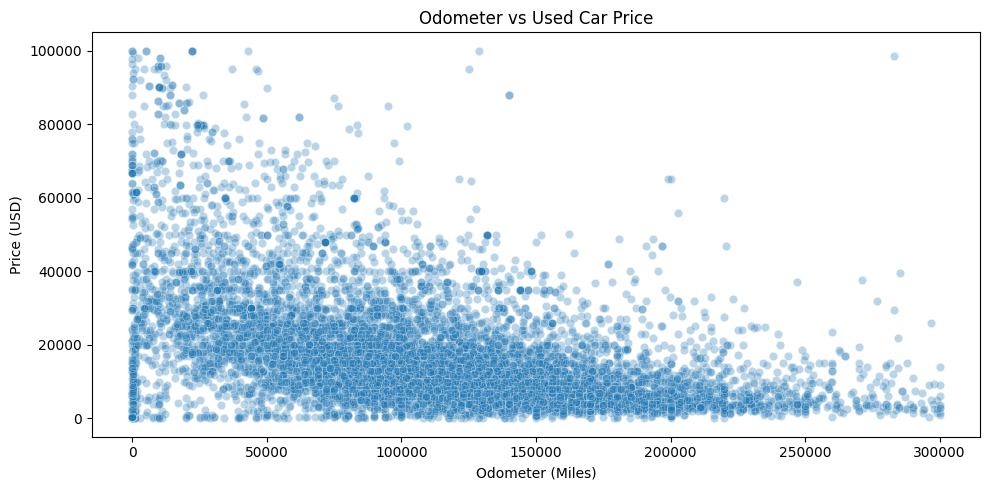

In [44]:

# Step 16: EDA - Odometer vs Price

import matplotlib.pyplot as plt
import seaborn as sns

# Filter data for visualization only
plot_data = df_prepared[
    (df_prepared["price"] <= 100000) &
    (df_prepared["odometer"] <= 300000) &
    (df_prepared["odometer"].notna())
]

# Sample 10,000 cars
plot_data = plot_data.sample(
    n=min(10000, len(plot_data)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=plot_data,
    x="odometer",
    y="price",
    alpha=0.3
)

plt.title("Odometer vs Used Car Price")
plt.xlabel("Odometer (Miles)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()


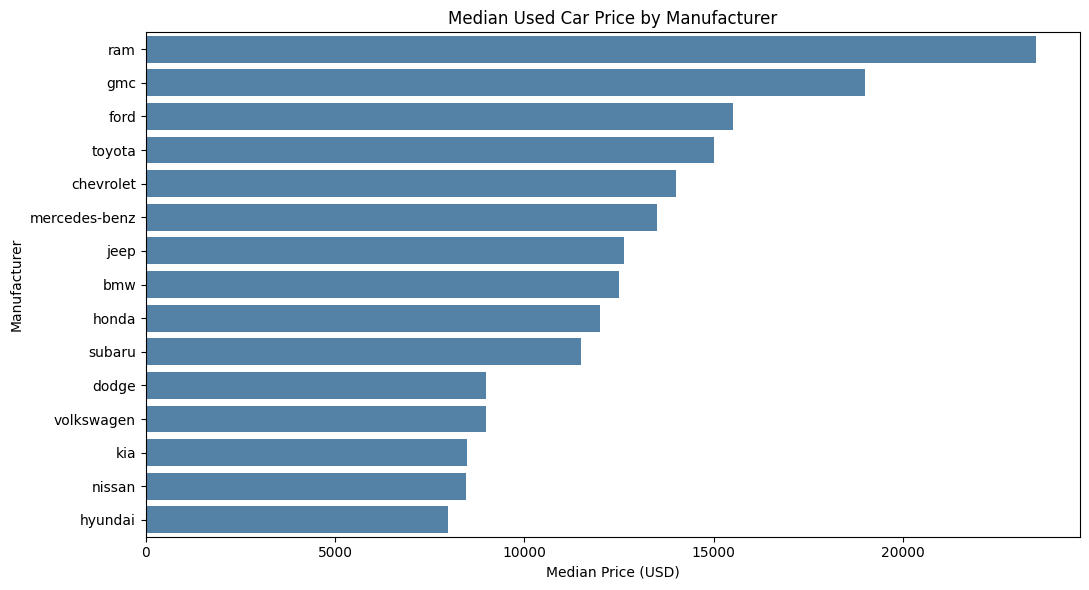

In [45]:

# Step 17: EDA - Price by Manufacturer

import matplotlib.pyplot as plt
import seaborn as sns

# Select the 15 most common manufacturers
top_brands = (
    df_prepared["manufacturer"]
    .value_counts()
    .head(15)
    .index
)

brand_data = df_prepared[
    df_prepared["manufacturer"].isin(top_brands)
]

# Calculate median price
brand_prices = (
    brand_data.groupby("manufacturer")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=brand_prices.values,
    y=brand_prices.index,
    color="steelblue"
)

plt.title("Median Used Car Price by Manufacturer")
plt.xlabel("Median Price (USD)")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()


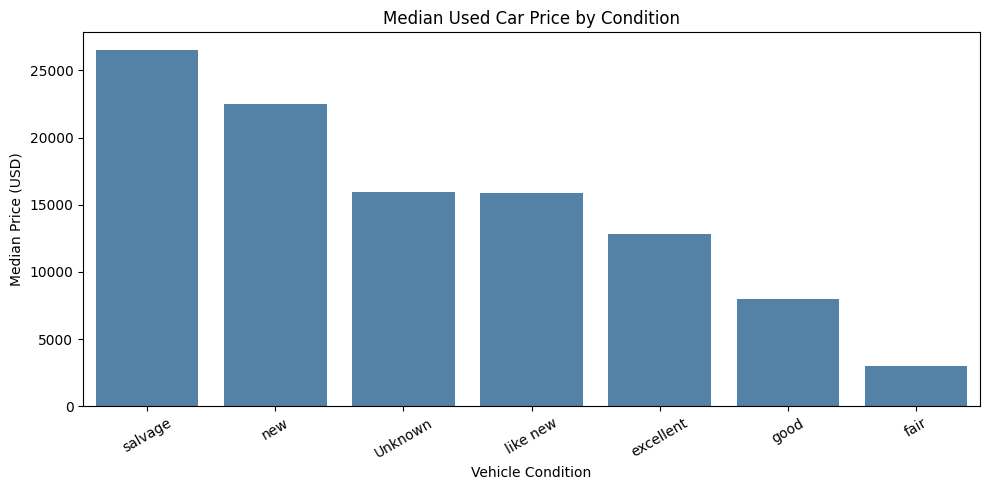

In [46]:

# Step 18: EDA - Price by Vehicle Condition

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare condition data for visualization
condition_data = df_prepared.copy()

condition_data["condition"] = (
    condition_data["condition"].fillna("Unknown")
)

# Calculate median price by condition
condition_prices = (
    condition_data.groupby("condition")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=condition_prices.index,
    y=condition_prices.values,
    color="steelblue"
)

plt.title("Median Used Car Price by Condition")
plt.xlabel("Vehicle Condition")
plt.ylabel("Median Price (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [47]:

# Step 19: Condition Analysis

condition_summary = (
    condition_data
    .groupby("condition")["price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(condition_summary.round(2))


,count,median,mean
condition,,,
salvage,1985,26500.0,27157.61
new,2292,22500.0,36692.69
Unknown,128651,15985.0,21203.52
like new,19223,15900.0,22278.63
excellent,75955,12800.0,17221.14
good,50547,8000.0,11666.72
fair,6424,3000.0,4428.12


In [48]:

# Step 20: Investigate Salvage Cars

condition_comparison = (
    condition_data
    .groupby("condition")
    .agg(
        car_count=("price", "size"),
        median_price=("price", "median"),
        median_year=("year", "median"),
        median_odometer=("odometer", "median")
    )
    .sort_values("median_price", ascending=False)
)

display(condition_comparison.round(2))


,car_count,median_price,median_year,median_odometer
condition,,,,
salvage,1985,26500.0,2019.0,119742.0
new,2292,22500.0,2019.0,49245.0
Unknown,128651,15985.0,2016.0,102286.0
like new,19223,15900.0,2017.0,84575.0
excellent,75955,12800.0,2015.0,109000.0
good,50547,8000.0,2012.0,129069.0
fair,6424,3000.0,2005.0,165000.0


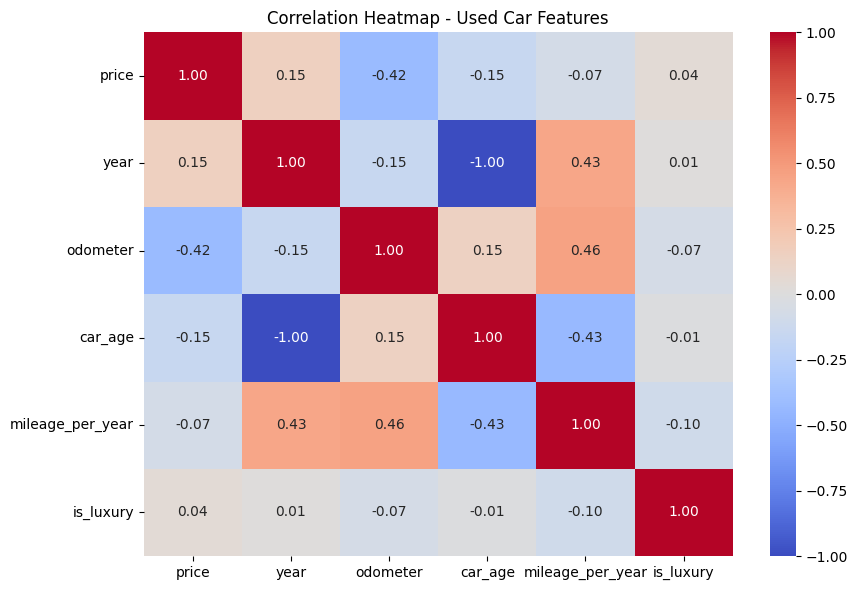

In [49]:

# Step 21: Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "price",
    "year",
    "odometer",
    "car_age",
    "mileage_per_year",
    "is_luxury"
]

correlation = df_prepared[numeric_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Used Car Features")
plt.tight_layout()
plt.show()


In [50]:

# Step 22: Final Data Quality Review

print("Original Dataset:", df.shape)
print("Prepared Dataset:", df_prepared.shape)

print("\nRemaining Missing Values:")
display(
    df_prepared.isnull().sum()
    .to_frame("Missing Count")
)

print("\nDuplicate Rows:")
print(df_prepared.duplicated().sum())

print("\nPrice Range:")
print(
    df_prepared["price"].min(),
    "-",
    df_prepared["price"].max()
)

print("\nInfinite Values:")
import numpy as np

numeric_data = df_prepared.select_dtypes(
    include="number"
)

print(
    np.isinf(numeric_data.to_numpy()).sum()
)


Original Dataset: (295451, 41)
Prepared Dataset: (285077, 18)

Remaining Missing Values:


,Missing Count
price,0
year,0
manufacturer,10448
model,3280
condition,128651
cylinders,76664
fuel,1020
odometer,4396
title_status,6631
transmission,1467



Duplicate Rows:
80661

Price Range:
1.0 - 1000000.0

Infinite Values:
0


In [51]:

# Step 23: Investigate Duplicate Records

print("Original Duplicate IDs:")
print(df["id"].duplicated().sum())

print("\nPrepared Duplicate Rows:")
print(df_prepared.duplicated().sum())

# Check duplicates using vehicle specifications
vehicle_columns = [
    "manufacturer",
    "model",
    "year",
    "odometer",
    "price",
    "state"
]

duplicate_vehicle_count = (
    df_prepared.duplicated(
        subset=vehicle_columns
    ).sum()
)

print("\nMatching Vehicle Specifications:")
print(duplicate_vehicle_count)

print("\nExample Matching Records:")
display(
    df_prepared[
        df_prepared.duplicated(
            subset=vehicle_columns,
            keep=False
        )
    ][vehicle_columns].head(10)
)


Original Duplicate IDs:
0

Prepared Duplicate Rows:
80661

Matching Vehicle Specifications:
83343

Example Matching Records:


,manufacturer,model,year,odometer,price,state
0,ford,explorer st,2022.0,99179.0,27999.0,ca
2,rover,sport,2016.0,82896.0,15999.0,ca
4,dodge,challenger lc srt8,2009.0,81724.0,18999.0,ca
5,ford,expedition max platinum,2020.0,96104.0,27999.0,ca
6,ford,explorer st-line,2023.0,54131.0,29999.0,ca
7,ford,mustang,2015.0,151055.0,17970.0,ca
8,kia,k5 gt-line,2023.0,62969.0,21999.0,ca
11,infiniti,g37,2009.0,83830.0,12999.0,ca
12,ford,f-250 f-series,2003.0,278282.0,5999.0,ca
13,chevrolet,tahoe lt,2018.0,88240.0,27999.0,ca


In [52]:

# Step 24: Investigate Duplicate VINs

vin_data = df.copy()

# Remove missing and empty VIN values
vin_data["VIN"] = (
    vin_data["VIN"]
    .astype("string")
    .str.strip()
    .str.upper()
)

vin_data = vin_data[
    vin_data["VIN"].notna() &
    (vin_data["VIN"] != "")
]

print("Records with VIN:", len(vin_data))

print("\nUnique VINs:")
print(vin_data["VIN"].nunique())

print("\nRepeated VIN Records:")
print(vin_data["VIN"].duplicated().sum())

print("\nTop 10 Most Repeated VINs:")
display(vin_data["VIN"].value_counts().head(10))


Records with VIN: 174332

Unique VINs:
90093

Repeated VIN Records:
84239

Top 10 Most Repeated VINs:


,count
VIN,
1FTNW21FXYED30441,167
1FTHF26G7VEA77606,159
1B7KF26C6SS150366,150
1FTNW21F1YEA14829,131
1FTWX33F9YEA12508,130
1GYS4GKL2RR104604,126
1FTHX26F6TEA44954,121
3D7LX38C36G177354,121
1D7KS28C26J203560,121


In [53]:

# Step 25: Analyze Repeated VIN Prices

import pandas as pd

vin_data["price"] = pd.to_numeric(
    vin_data["price"], errors="coerce"
)

vin_summary = (
    vin_data.groupby("VIN")
    .agg(
        listing_count=("id", "count"),
        unique_prices=("price", "nunique"),
        min_price=("price", "min"),
        max_price=("price", "max")
    )
)

repeated_vins = vin_summary[
    vin_summary["listing_count"] > 1
]

print("VINs with Multiple Listings:")
print(len(repeated_vins))

print("\nRepeated VINs with Different Prices:")
print((repeated_vins["unique_prices"] > 1).sum())

print("\nRepeated VINs with Same Price:")
print((repeated_vins["unique_prices"] == 1).sum())

print("\nTop 10 Repeated VINs:")
display(
    repeated_vins.sort_values(
        "listing_count", ascending=False
    ).head(10)
)


VINs with Multiple Listings:
29996

Repeated VINs with Different Prices:
4885

Repeated VINs with Same Price:
25111

Top 10 Repeated VINs:


,listing_count,unique_prices,min_price,max_price
VIN,,,,
1FTNW21FXYED30441,167,1,39997.0,39997.0
1FTHF26G7VEA77606,159,1,47997.0,47997.0
1B7KF26C6SS150366,150,1,49997.0,49997.0
1FTNW21F1YEA14829,131,1,34997.0,34997.0
1FTWX33F9YEA12508,130,2,34997.0,36997.0
1GYS4GKL2RR104604,126,2,79797.0,82997.0
3D7LX38C36G177354,121,1,36997.0,36997.0
1D7KS28C26J203560,121,2,39997.0,41997.0
1FTHX26F6TEA44954,121,2,42997.0,44997.0


In [54]:

# Step 26: Final Data Cleaning

import pandas as pd
import numpy as np

# Work from the cleaned dataset
final_df = df_prepared.copy()

# Restore identifiers for duplicate handling
final_df["VIN"] = df_clean.loc[final_df.index, "VIN"]
final_df["posting_date"] = df_clean.loc[
    final_df.index, "posting_date"
]

# Normalize VIN
final_df["VIN"] = (
    final_df["VIN"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Keep only valid-looking VINs for deduplication
valid_vin = final_df["VIN"].str.fullmatch(
    r"[A-HJ-NPR-Z0-9]{17}"
).fillna(False)

# Parse posting dates
final_df["posting_date"] = pd.to_datetime(
    final_df["posting_date"],
    errors="coerce",
    utc=True
)

# Deduplicate valid VINs, keeping latest listing
with_vin = final_df[valid_vin].copy()
without_vin = final_df[~valid_vin].copy()

with_vin = (
    with_vin.sort_values("posting_date")
    .drop_duplicates(subset="VIN", keep="last")
)

final_df = pd.concat(
    [with_vin, without_vin]
).sort_index()

# Remove very low prices
final_df = final_df[
    final_df["price"] >= 500
].copy()

# Fill missing categorical values
categorical_cols = final_df.select_dtypes(
    include=["object", "string"]
).columns.difference(["VIN", "posting_date"])

final_df[categorical_cols] = (
    final_df[categorical_cols].fillna("Unknown")
)

# Preserve unknown luxury status
final_df.loc[
    final_df["manufacturer"] == "Unknown",
    "is_luxury"
] = np.nan

# Remove temporary identifiers
final_df = final_df.drop(
    columns=["VIN", "posting_date"]
)

print("Final Dataset Shape:", final_df.shape)
print("Remaining Missing Values:")
print(final_df.isnull().sum())
print("Duplicate Feature Rows:",
      final_df.duplicated().sum())


Final Dataset Shape: (202316, 18)
Remaining Missing Values:
price                  0
year                   0
manufacturer           0
model                  0
condition              0
cylinders              0
fuel                   0
odometer            3712
title_status           0
transmission           0
drive                  0
type                   0
paint_color            0
state                  0
seller_type            0
car_age                0
mileage_per_year    3712
is_luxury           8744
dtype: int64
Duplicate Feature Rows: 21621


In [55]:

# Step 27: Save Final Dataset

final_df.to_csv(
    "used_cars_cleaned.csv",
    index=False
)

print("Dataset saved successfully!")
print("Final Shape:", final_df.shape)


Dataset saved successfully!
Final Shape: (202316, 18)
